# Whitelam–Klymko–Mandal lattice active matter

$Pe=(v_+-v_-)/(2D_{rot})$

In [19]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.7.1+cu126 | device: cuda


In [20]:
try:
    from numba import njit
except ImportError:
    njit = lambda f: f

@njit
def _wkm_events(occupied, positions, directions, rates, L, burn_events,
                total_events, sample_interval, seed):
    np.random.seed(seed)
    N = len(positions)
    total_rate = rates.sum()
    offsets = np.array([0, 1, 3, 2])
    t, f4_sum, f4_sq_sum, n_samples = 0.0, 0.0, 0.0, 0
    for event in range(total_events):
        particle = np.random.randint(N)
        r = np.random.random()*total_rate
        kind = 0
        while r >= rates[kind]:
            r -= rates[kind]
            kind += 1
        if kind < 4:
            direction = (directions[particle]+offsets[kind]) % 4
            old = positions[particle]
            y, x = old//L, old%L
            if direction == 0:
                x = (x+1)%L
            elif direction == 1:
                y = (y+1)%L
            elif direction == 2:
                x = (x-1+L)%L
            else:
                y = (y-1+L)%L
            new = y*L+x
            if occupied[new] == 0:
                occupied[old] = 0
                occupied[new] = particle+1
                positions[particle] = new
        else:
            directions[particle] = (directions[particle] + (1 if kind == 4 else 3)) % 4
        t -= np.log(max(np.random.random(), 1e-12))/(N*total_rate)
        if event >= burn_events and (event-burn_events) % sample_interval == 0:
            jammed = 0
            for y in range(L):
                for x in range(L):
                    if (occupied[y*L+x] != 0 and
                        occupied[y*L+(x+1)%L] != 0 and
                        occupied[y*L+(x-1+L)%L] != 0 and
                        occupied[((y+1)%L)*L+x] != 0 and
                        occupied[((y-1+L)%L)*L+x] != 0):
                        jammed += 1
            f4 = jammed/N
            f4_sum += f4
            f4_sq_sum += f4*f4
            n_samples += 1
    mean = f4_sum/n_samples
    return mean, max(f4_sq_sum/n_samples-mean*mean, 0.0), t

def wkm(L, phi, v_plus, v0=1.0, v_minus=0.1, Drot=0.1,
        burn_sweeps=500, sample_sweeps=1000, sample_every=10, seed=0):
    assert L > 1 and 0 < phi < 1 and sample_sweeps >= sample_every
    rng = np.random.default_rng(seed)
    N = round(phi*L*L)
    positions = rng.permutation(L*L)[:N].astype(np.int32)
    directions = rng.integers(0, 4, N, dtype=np.int32)
    occupied = np.zeros(L*L, dtype=np.int32)
    occupied[positions] = np.arange(1, N+1)
    rates = np.array([v_plus, v0, v0, v_minus, Drot, Drot], dtype=np.float64)
    burn_events = N*burn_sweeps
    mean, variance, t = _wkm_events(occupied, positions, directions, rates, L,
                           burn_events, N*(burn_sweeps+sample_sweeps),
                           N*sample_every, seed)
    return torch.from_numpy((occupied.reshape(L, L) != 0)).to(device), mean, variance, t

L = 100
densities = np.linspace(.1, .5, 9)
v_plus_grid = np.arange(1., 26., 2.)
Drot, v_minus, v0 = .1, 1., 1.
means = np.empty((len(v_plus_grid), len(densities)))
variances = np.empty_like(means)
for i, v_plus in enumerate(v_plus_grid):
    for j, phi in enumerate(densities):
        _, means[i, j], variances[i, j], _ = wkm(
            L, phi, v_plus, v0=v0, v_minus=v_minus, Drot=Drot,
            seed=100*i+j)
log_variances = np.log(np.maximum(variances, 1e-12))

size_density = .15
sizes = (16, 32, 64, 128, 256, 512)
size_v_plus = np.arange(5., 26., 2.)
size_variances = np.empty((len(sizes), len(size_v_plus), 3))
for i, size in enumerate(sizes):
    for j, v_plus in enumerate(size_v_plus):
        for run in range(3):
            _, _, size_variances[i, j, run], _ = wkm(
                size, size_density, v_plus, v0=v0, v_minus=v_minus,
                Drot=Drot, seed=10000*i+100*j+run)
size_log_variances = np.log(np.maximum(size_variances.mean(2), 1e-12))
size_log_errors = size_variances.std(2, ddof=1) / (
    np.sqrt(3)*np.maximum(size_variances.mean(2), 1e-12))
print('WKM f4 phase maps and size scan completed')

WKM f4 phase maps and size scan completed


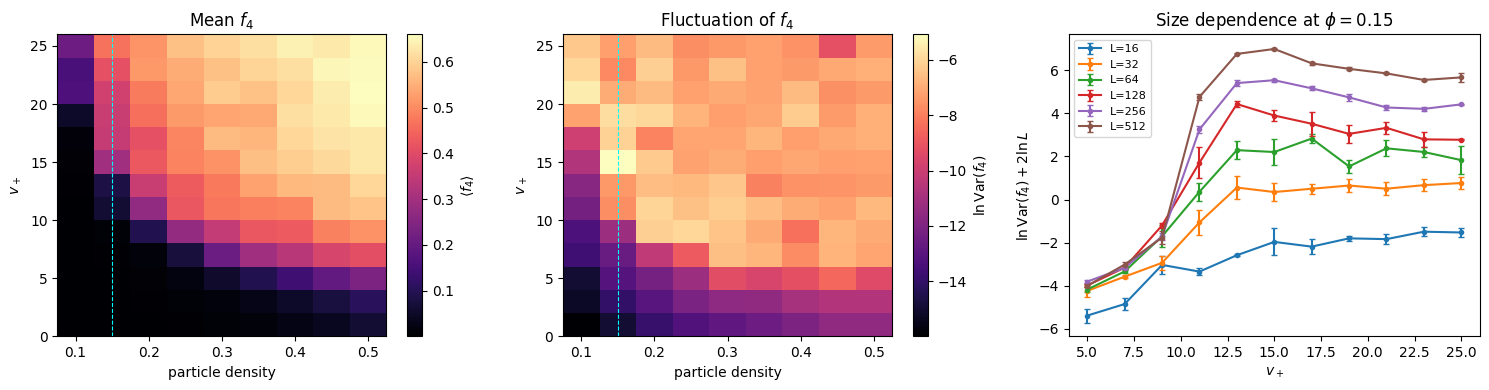

In [22]:
sigma = v_plus_grid + v_minus + 2*v0 + 2*Drot
kappa = (1-(1-2*Drot/sigma)**(2*sigma/Drot))/4
pe = (v_plus_grid-v_minus)/(2*Drot)
phase_fraction = (pe[:, None]*kappa[:, None]-1/densities[None, :]) / (
    pe[:, None]*kappa[:, None]-1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, data, title, label in zip(ax[:2], [means, log_variances],
                                  [r'Mean $f_4$', r'Fluctuation of $f_4$'],
                                  [r'$\langle f_4\rangle$', r'$\ln\operatorname{Var}(f_4)$']):
    im = a.pcolormesh(densities, v_plus_grid, data, shading='nearest', cmap='magma')
    a.axvline(size_density, color='cyan', ls='--', lw=.8)
    a.set(xlabel='particle density', ylabel=r'$v_+$', title=title)
    fig.colorbar(im, ax=a, label=label)
for i, size in enumerate(sizes):
    ax[2].errorbar(size_v_plus, size_log_variances[i] + 2*np.log(size),
                   yerr=size_log_errors[i], marker='o', ms=3,
                   capsize=2, label=f'L={size}')
ax[2].set(xlabel=r'$v_+$', ylabel=r'$\ln\operatorname{Var}(f_4) + 2 \ln L$',
          title=fr'Size dependence at $\phi={size_density}$')
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()